In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import build_model, halofit

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

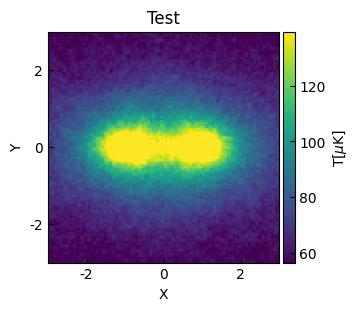

In [3]:
coord = get_coord()

data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
plot_heatmap(data, title='Test')

In [ ]:
name = 'gaussian'
bg_name = 'poly'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 500),
    'amplitude_1': (0, 500),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'x_stddev_0': (0, 1),
    'y_stddev_0': (0, 1),
    'x_stddev_1': (0, 1),
    'y_stddev_1': (0, 1),
}

constraints = {
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0")  # amplitude_1 = amplitude_0
    ]
}

model = build_model(name, bg_name, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [1]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [2]: <Polynomial2D(2, c0_0=0., c1_0=0., c2_0=0., c0_1=0., c0_2=0., c1_1=0., x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 x_stddev_0 ... c2_0_2 c0_1_2 c0_2_2 c1_1_2
    ----------- -------- -------- ---------- ... ------ ------ ------ ------
           50.0     -1.0      0.0        0.5 ...    0.0    0.0    0.0    0.0


# without mask

In [5]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=149.7832655, x_mean=-1., y_mean=0., x_stddev=0.59355758, y_stddev=0.52803297, theta=0.24052496)>

    [1]: <Gaussian2D(amplitude=149.7832655, x_mean=1., y_mean=0., x_stddev=0.61415259, y_stddev=0.52893329, theta=0.07634926)>

    [2]: <Polynomial2D(2, c0_0=57.90961966, c1_0=-0.62807831, c2_0=10.40068068, c0_1=-0.268874, c0_2=7.64997772, c1_1=-0.44728153, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       c0_2_2             c1_1_2      
    ------------------ -------- -------- ... ----------------- -------------------
    149.78326550453198     -1.0      0.0 ... 7.649977716653899 -0.4472815314877934

Goodness of fit:
Chi-squared: 17838694.362
RMS residual: 35.197


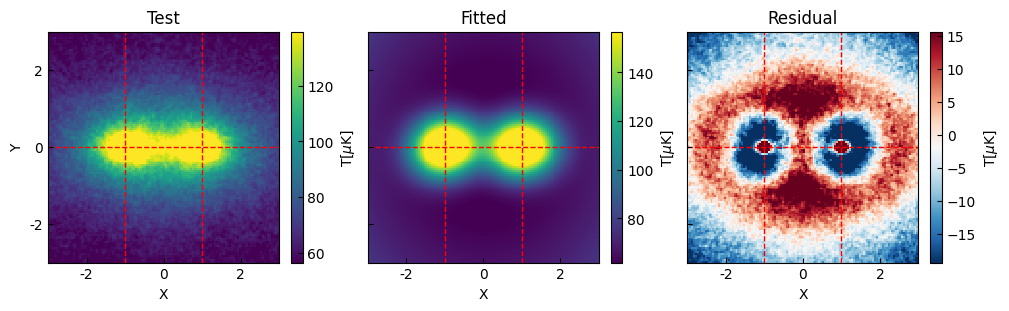

In [6]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

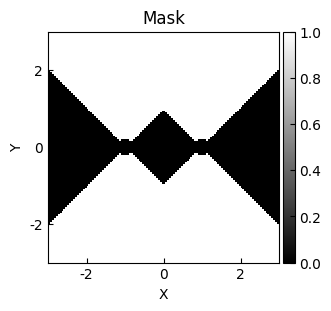

In [7]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [8]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=132.81185236, x_mean=-1., y_mean=0., x_stddev=0.99603626, y_stddev=0.99958309, theta=0.0037441)>

    [1]: <Gaussian2D(amplitude=132.81185236, x_mean=1., y_mean=0., x_stddev=0.99402517, y_stddev=0.99980874, theta=0.00530638)>

    [2]: <Polynomial2D(2, c0_0=3.36368653, c1_0=0.11611144, c2_0=8.02667865, c0_1=-0.03813003, c0_2=14.13232048, c1_1=-0.06952572, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...       c0_2_2              c1_1_2       
    ------------------ -------- -------- ... ------------------ --------------------
    132.81185236337754     -1.0      0.0 ... 14.132320480529156 -0.06952571671623552

Goodness of fit:
Chi-squared: 31844825.781
RMS residual: 47.026


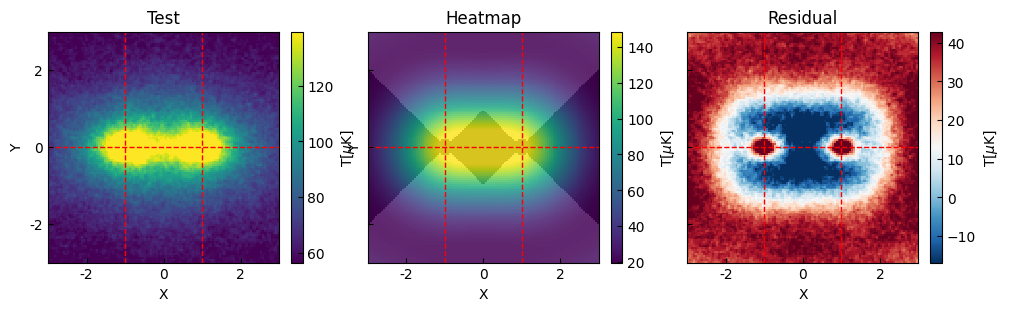

In [9]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

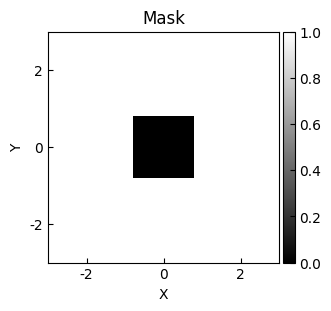

In [10]:
mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [11]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=422.17202664, x_mean=-1., y_mean=0., x_stddev=0.12967062, y_stddev=0.13630818, theta=7.84164513)>

    [1]: <Gaussian2D(amplitude=422.17202664, x_mean=1., y_mean=0., x_stddev=0.13693171, y_stddev=0.12832546, theta=3.17136812)>

    [2]: <Polynomial2D(2, c0_0=87.23068765, c1_0=0.1621227, c2_0=-5.26178177, c0_1=-0.28379914, c0_2=-30.90925119, c1_1=-0.5870781, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        c0_2_2              c1_1_2      
    ----------------- -------- -------- ... ------------------- -------------------
    422.1720266384985     -1.0      0.0 ... -30.909251186141802 -0.5870780982326833

Goodness of fit:
Chi-squared: 14410432.264
RMS residual: 31.634


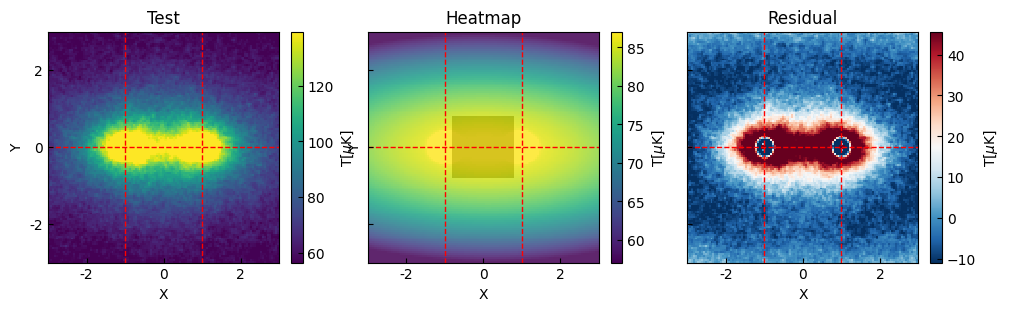

In [12]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [13]:
from mytools.plot import plot_hist

(-100.0, 100.0)

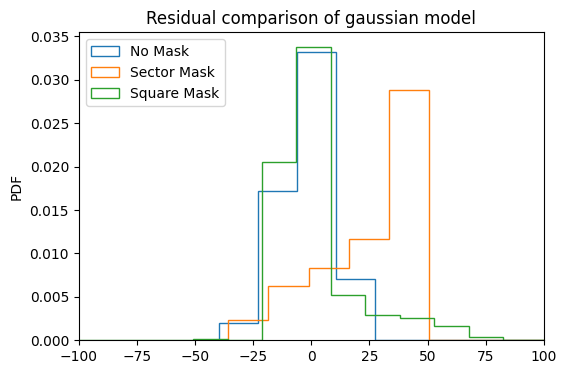

In [14]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [15]:
from mytools.plot import plot_line,plt

In [16]:
stack_fit_res = data_list_sector

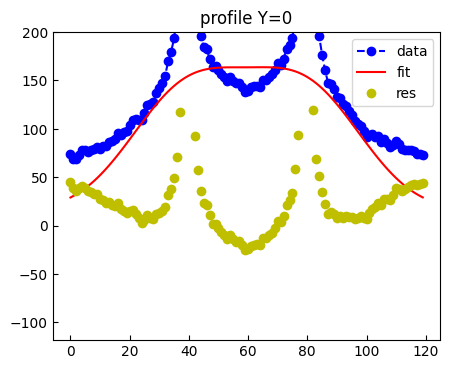

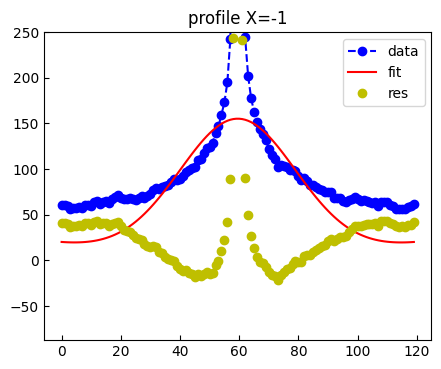

In [17]:
xx = [range(120)]*3

ind = 60
yy = [d[ind] for d in stack_fit_res]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.ylim(ymax=200)
plt.legend()

ind = 40
yy = [d[:, ind] for d in stack_fit_res]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.ylim(ymax=250)
plt.legend()

# estimate signal level

In [18]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Gauss fit parameters a, sgima, c (and mu): [-64.1475762    0.5         25.52653848]
Gauss fit covariance of a, sgima, c (and mu): [[ 2.56105254e+01  9.04321697e-02 -2.90179392e+00]
 [ 9.04321697e-02  2.40704072e-03  4.52362097e-02]
 [-2.90179392e+00  4.52362097e-02  4.10375586e+00]]
width: 0.49999999999999994
width_pix: 10


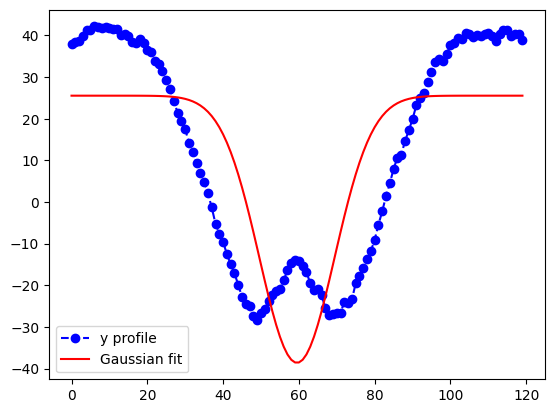

In [19]:
res = stack_fit_res[-1]
# bounds = (
#     [-np.inf, 0, -np.inf],
#     [np.inf, 1, np.inf],
# )
lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

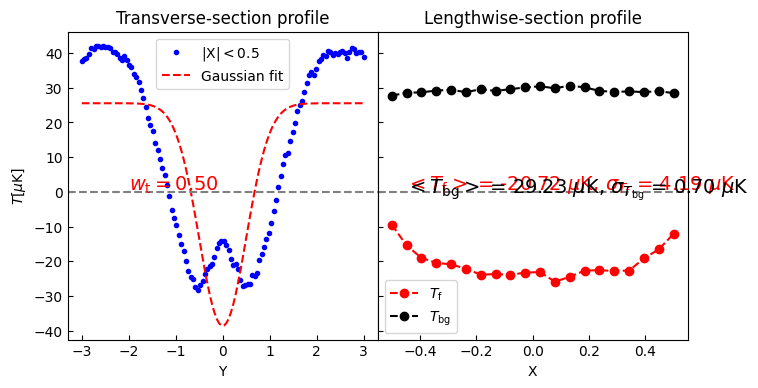

In [20]:
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[1])

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

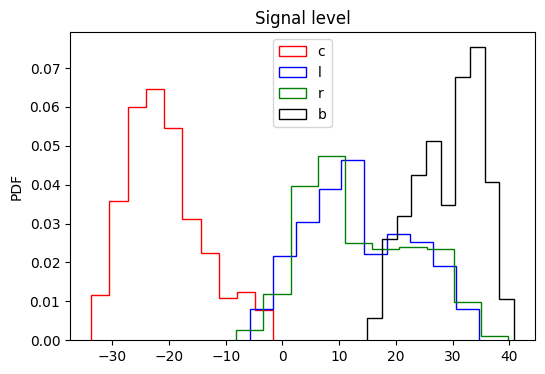

In [21]:
plot_hist(clrb, label=['c','l','r','b'], color=['r', 'b','g','k'], title='Signal level')